# Lecture 6 — Class Exercise: Choropleth Maps
Completed using the Plotly Express approach in lecture06_notes.ipynb.

**Contents:** Task 1 — life expectancy relative to the global mean; Task 2 — a custom GeoJSON map of US state population density. Both tasks include data checks, design decisions, interactive charts, saved chart pictures, and interpretations.

**Kaggle:** Import this .ipynb, then select **Run All**. No dataset upload is needed: Gapminder is bundled with Plotly and the GeoJSON is embedded. Saved pictures are visible without running the notebook. Interactive maps may require internet access to Plotly's geographic assets. This notebook was executed locally, not on Kaggle.

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import json
import gzip
import base64
from pathlib import Path
from IPython.display import display, Markdown

px.defaults.template = 'plotly_white'
pd.options.display.float_format = '{:,.2f}'.format
OUTPUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('chart_exports')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def show_and_save(fig, name):
    # Preserve interactive chart data in notebook outputs.
    fig.show(renderer='plotly_mimetype')
    fig.write_html(OUTPUT_DIR / f'{name}.html', include_plotlyjs=True)
    print(f'Interactive HTML saved: {name}.html')

## Task 1 — World choropleth: life expectancy diverging scale
**Requirements:** Gapminder 2007; each country's deviation from the global mean; a diverging scale centred at zero; country, life expectancy and deviation on hover; a title identifying the region furthest below average.

### Design decisions
- **Chart:** px.choropleth with built-in world geometry and ISO-3 codes. A world projection makes continental patterns visible; street tiles are unnecessary.
- **Colour:** diverging RdBu: red below the mean, white near zero, blue above. Symmetric limits make equal absolute deviations equally far from the midpoint.
- **Mean:** the exercise specifies the unweighted mean across countries in the dataset. It is not population-weighted and does not represent every country or person worldwide.
- **Regional claim:** compare unweighted continent means to support the title. Grey areas have no observation.

In [2]:
gm = px.data.gapminder()
gm_2007 = gm.loc[gm['year'].eq(2007)].copy()
# Some Plotly releases incorrectly assign KOR to both Koreas.
# Correct only the geographic identifiers, leaving measurements unchanged.
gm_2007.loc[gm_2007['country'].eq('Korea, Dem. Rep.'), ['iso_alpha', 'iso_num']] = ['PRK', 408]
gm_2007.loc[gm_2007['country'].eq('Korea, Rep.'), ['iso_alpha', 'iso_num']] = ['KOR', 410]
assert len(gm_2007) == 142 and gm_2007['iso_alpha'].is_unique
assert gm_2007[['lifeExp', 'iso_alpha', 'continent']].notna().all().all()

global_mean = gm_2007['lifeExp'].mean()
gm_2007['deviation'] = gm_2007['lifeExp'] - global_mean
assert np.isclose(gm_2007['deviation'].mean(), 0)

continent_summary = (gm_2007.groupby('continent', as_index=False)
    .agg(countries=('country', 'size'), mean_life_expectancy=('lifeExp', 'mean'),
         mean_deviation=('deviation', 'mean'))
    .sort_values('mean_deviation'))
lowest_region = continent_summary.iloc[0]
print(f'Countries: {len(gm_2007)} | Year: 2007')
print(f'Unweighted global country mean: {global_mean:.2f} years')
display(continent_summary.round(2))
display(gm_2007[['country', 'continent', 'iso_alpha', 'lifeExp', 'deviation']].head())

Countries: 142 | Year: 2007
Unweighted global country mean: 67.01 years


,continent,countries,mean_life_expectancy,mean_deviation
0,Africa,52,54.81,-12.20
2,Asia,33,70.73,3.72
1,Americas,25,73.61,6.60
3,Europe,30,77.65,10.64
4,Oceania,2,80.72,13.71


,country,continent,iso_alpha,lifeExp,deviation
11,Afghanistan,Asia,AFG,43.83,-23.18
23,Albania,Europe,ALB,76.42,9.42
35,Algeria,Africa,DZA,72.30,5.29
47,Angola,Africa,AGO,42.73,-24.28
59,Argentina,Americas,ARG,75.32,8.31


In [3]:
limit = float(gm_2007['deviation'].abs().max())
fig_world = px.choropleth(
    gm_2007, locations='iso_alpha', locationmode='ISO-3', color='deviation',
    color_continuous_scale='RdBu', color_continuous_midpoint=0,
    range_color=(-limit, limit),
    hover_name='country',
    hover_data={'iso_alpha': False, 'continent': True, 'lifeExp': ':.2f', 'deviation': '+.2f'},
    labels={'lifeExp': 'Life expectancy (years)', 'deviation': 'Difference (years)',
            'continent': 'Continent'},
    title=f"{lowest_region['continent']} is furthest below the global country mean",
    projection='natural earth', height=610, width=1100,
)
fig_world.update_traces(marker_line_color='white', marker_line_width=0.4)
fig_world.update_geos(showframe=False, showcoastlines=False,
                     showland=True, landcolor='#e5e7eb', bgcolor='white')
fig_world.update_layout(
    font=dict(family='Arial', size=13),
    title=dict(x=0.04, y=0.96, font=dict(size=24)),
    margin=dict(l=20, r=30, t=100, b=65),
    coloraxis_colorbar=dict(title='Years vs mean', thickness=16, len=0.7),
)
fig_world.add_annotation(x=0.02, y=1.09, xref='paper', yref='paper', showarrow=False,
    text=f'Gapminder 2007 | Mean = {global_mean:.2f} years | Red: below; blue: above',
    font=dict(size=14, color='#475569'))
fig_world.add_annotation(x=0, y=-0.08, xref='paper', yref='paper', showarrow=False,
    text='Source: Plotly / Gapminder. 142 countries, equal country weights. Grey = no data.',
    font=dict(size=12, color='#64748b'))
show_and_save(fig_world, 'task1_world_life_expectancy')

Interactive HTML saved: task1_world_life_expectancy.html


### Task 1 — Saved chart picture
Static companion map with the same data and colour limits. Its equirectangular projection differs from the interactive Natural Earth projection. Reproduction code is included below.

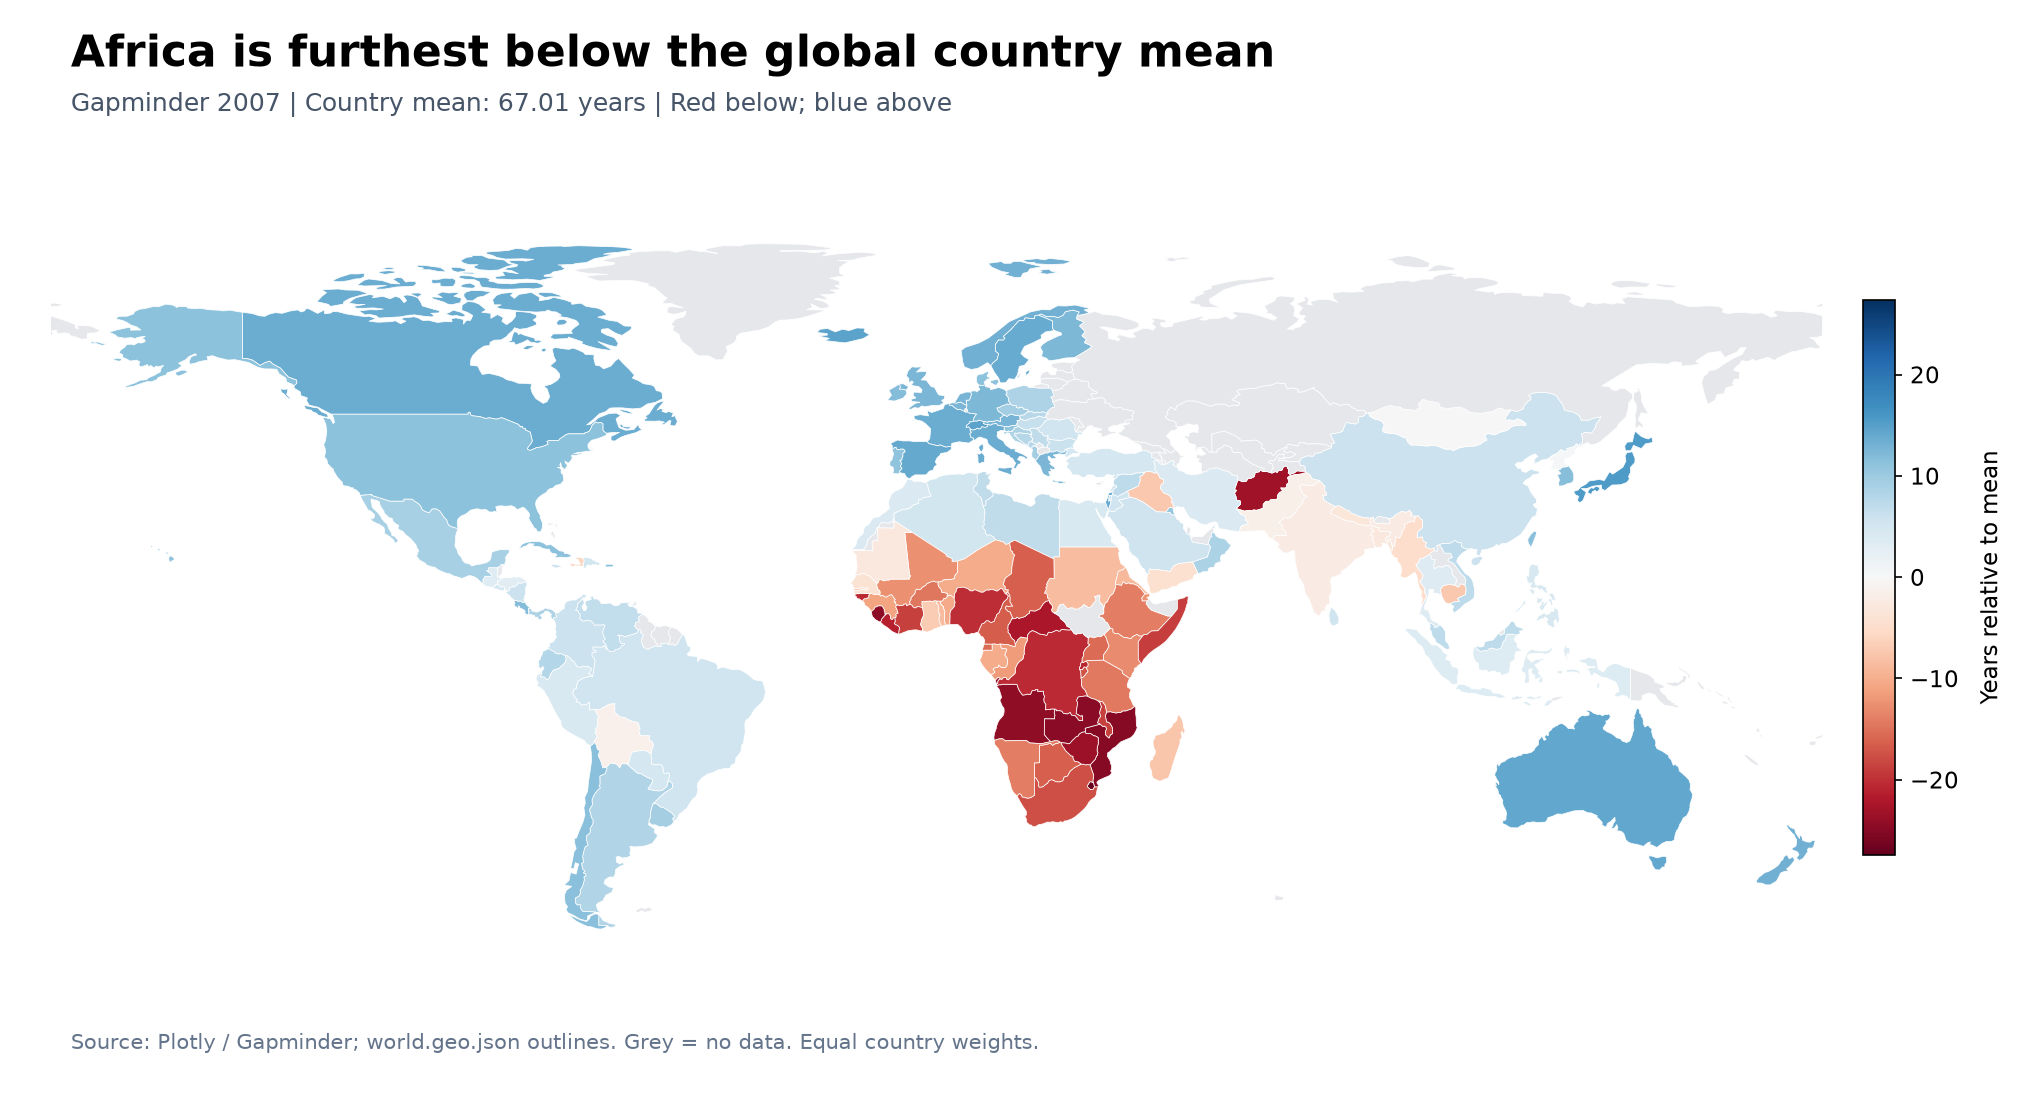

In [4]:
# Display a bundled PNG as a standard notebook image output.
# This works without attachment support, internet access, or extra files.
import base64
from IPython.display import Image, display
chart_png_base64 = (
    '...'
)
display(Image(data=base64.b64decode(chart_png_base64), format="png", width=1000))

In [5]:
low = gm_2007.loc[gm_2007['lifeExp'].idxmin()]
high = gm_2007.loc[gm_2007['lifeExp'].idxmax()]
display(Markdown(
    f"**Interpretation.** The global country mean is **{global_mean:.2f} years**. "
    f"{lowest_region['continent']} has the lowest continent mean "
    f"(**{lowest_region['mean_life_expectancy']:.2f} years**), "
    f"**{abs(lowest_region['mean_deviation']):.2f} years below** the reference. "
    "The red concentration across much of Africa is supported by the grouped data. "
    "Europe and Oceania are generally above the reference. "
    f"The lowest country value is {low['country']} ({low['lifeExp']:.2f} years); "
    f"the highest is {high['country']} ({high['lifeExp']:.2f} years).\n\n"
    "**Limits.** Continent averages hide variation between countries; Oceania has only two "
    "countries in the sample. These are 2007 observations, not current estimates or causal explanations."
))

**Interpretation.** The global country mean is **67.01 years**. Africa has the lowest continent mean (**54.81 years**), **12.20 years below** the reference. The red concentration across much of Africa is supported by the grouped data. Europe and Oceania are generally above the reference. The lowest country value is Swaziland (39.61 years); the highest is Japan (82.60 years).

**Limits.** Continent averages hide variation between countries; Oceania has only two countries in the sample. These are 2007 observations, not current estimates or causal explanations.

## Task 2 — Find your own GeoJSON
Use online boundary data, inspect its properties, create matching numeric data and explain the mapping choices.

### Task 2 — Design decisions
**GeoJSON source:** [PublicaMundi MappingAPI — us-states.json](https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json). A downloaded snapshot is embedded below for reproducibility.

**Dataset:** the numeric density property in that file, measured in people per square mile. The [Leaflet choropleth tutorial](https://leafletjs.com/examples/choropleth/) documents this example dataset's density values as based on July 2011 data. Treat the values as a historical teaching snapshot, not current population statistics. Keep the 50 states, excluding the District of Columbia and Puerto Rico.

**Chart chosen:** px.choropleth, with custom GeoJSON and the Albers USA projection. It shows all states, including Alaska and Hawaii as insets, without street tiles or an API token. This follows the lecture's custom-geometry approach.

**Feature matching:** inspect feature properties, then match the dataframe's State column with featureidkey='properties.name'. Explicit checks below verify unique names and complete matching.

**Colour chosen:** sequential YlGnBu because density is a non-negative magnitude with no meaningful central reference. A linear scale starting at zero preserves numerical differences. Density is more appropriate than raw population totals for a choropleth because it normalizes by area. Smaller differences at the low end are harder to see, so a sorted table supplements the map.

In [6]:
# A compressed snapshot avoids a separate file upload or runtime download.
# To refresh intentionally with internet enabled:
# from urllib.request import urlopen
# with urlopen(GEOJSON_URL) as response:
#     my_geojson = json.load(response)
GEOJSON_URL = 'https://raw.githubusercontent.com/PublicaMundi/MappingAPI/master/data/geojson/us-states.json'
GEOJSON_GZIP_BASE64 = '...'

my_geojson = json.loads(gzip.decompress(base64.b64decode(GEOJSON_GZIP_BASE64)))
print('First feature properties:', my_geojson['features'][0]['properties'])
print('Original features:', len(my_geojson['features']))

excluded = {'District of Columbia', 'Puerto Rico'}
state_geojson = {'type': 'FeatureCollection', 'features': [
    f for f in my_geojson['features'] if f['properties']['name'] not in excluded
]}
state_data = pd.DataFrame([
    {'State': f['properties']['name'], 'Density': f['properties']['density']}
    for f in state_geojson['features']
])
state_data['Density'] = pd.to_numeric(state_data['Density'], errors='raise')
geo_names = [f['properties']['name'] for f in state_geojson['features']]
assert len(geo_names) == len(set(geo_names)) == 50
assert state_data['State'].is_unique
assert set(state_data['State']) == set(geo_names)
assert state_data['Density'].notna().all() and state_data['Density'].ge(0).all()
print('Join verified: 50 data rows match 50 GeoJSON features via properties.name.')
display(state_data.sort_values('Density', ascending=False).head(10))

First feature properties: {'name': 'Alabama', 'density': 94.65}
Original features: 52
Join verified: 50 data rows match 50 GeoJSON features via properties.name.


,State,Density
29,New Jersey,"1,189.00"
38,Rhode Island,"1,006.00"
20,Massachusetts,840.20
6,Connecticut,739.10
19,Maryland,596.30
7,Delaware,464.30
31,New York,412.30
8,Florida,353.40
37,Pennsylvania,284.30
34,Ohio,281.90


In [7]:
fig_states = px.choropleth(
    state_data, geojson=state_geojson, locations='State',
    featureidkey='properties.name', color='Density',
    color_continuous_scale='YlGnBu',
    range_color=(0, float(state_data['Density'].max())),
    scope='usa', projection='albers usa',
    hover_name='State', hover_data={'State': False, 'Density': ':,.2f'},
    labels={'Density': 'People per square mile'},
    title='Northeastern states are dense; New Jersey leads the 50 states',
    height=650, width=1100,
)
fig_states.update_traces(marker_line_color='white', marker_line_width=0.7)
fig_states.update_geos(showframe=False, showcoastlines=False, showlakes=False, bgcolor='white')
fig_states.update_layout(
    font=dict(family='Arial', size=13),
    title=dict(x=0.04, y=0.96, font=dict(size=23)),
    margin=dict(l=20, r=30, t=105, b=70),
    coloraxis_colorbar=dict(title='People / mi²', thickness=16, len=0.7),
)
fig_states.add_annotation(x=0.02, y=1.09, xref='paper', yref='paper', showarrow=False,
    text='Historical population density snapshot | 50 states | Linear sequential scale',
    font=dict(size=14, color='#475569'))
fig_states.add_annotation(x=0, y=-0.09, xref='paper', yref='paper', showarrow=False,
    text='Source: PublicaMundi / Leaflet example data. DC and Puerto Rico excluded. Alaska and Hawaii are insets.',
    font=dict(size=11, color='#64748b'))
show_and_save(fig_states, 'task2_us_state_density')

Interactive HTML saved: task2_us_state_density.html


### Task 2 — Saved chart picture
Static companion map with Alaska and Hawaii insets; the interactive chart above uses Albers USA. Reproduction code is included below.

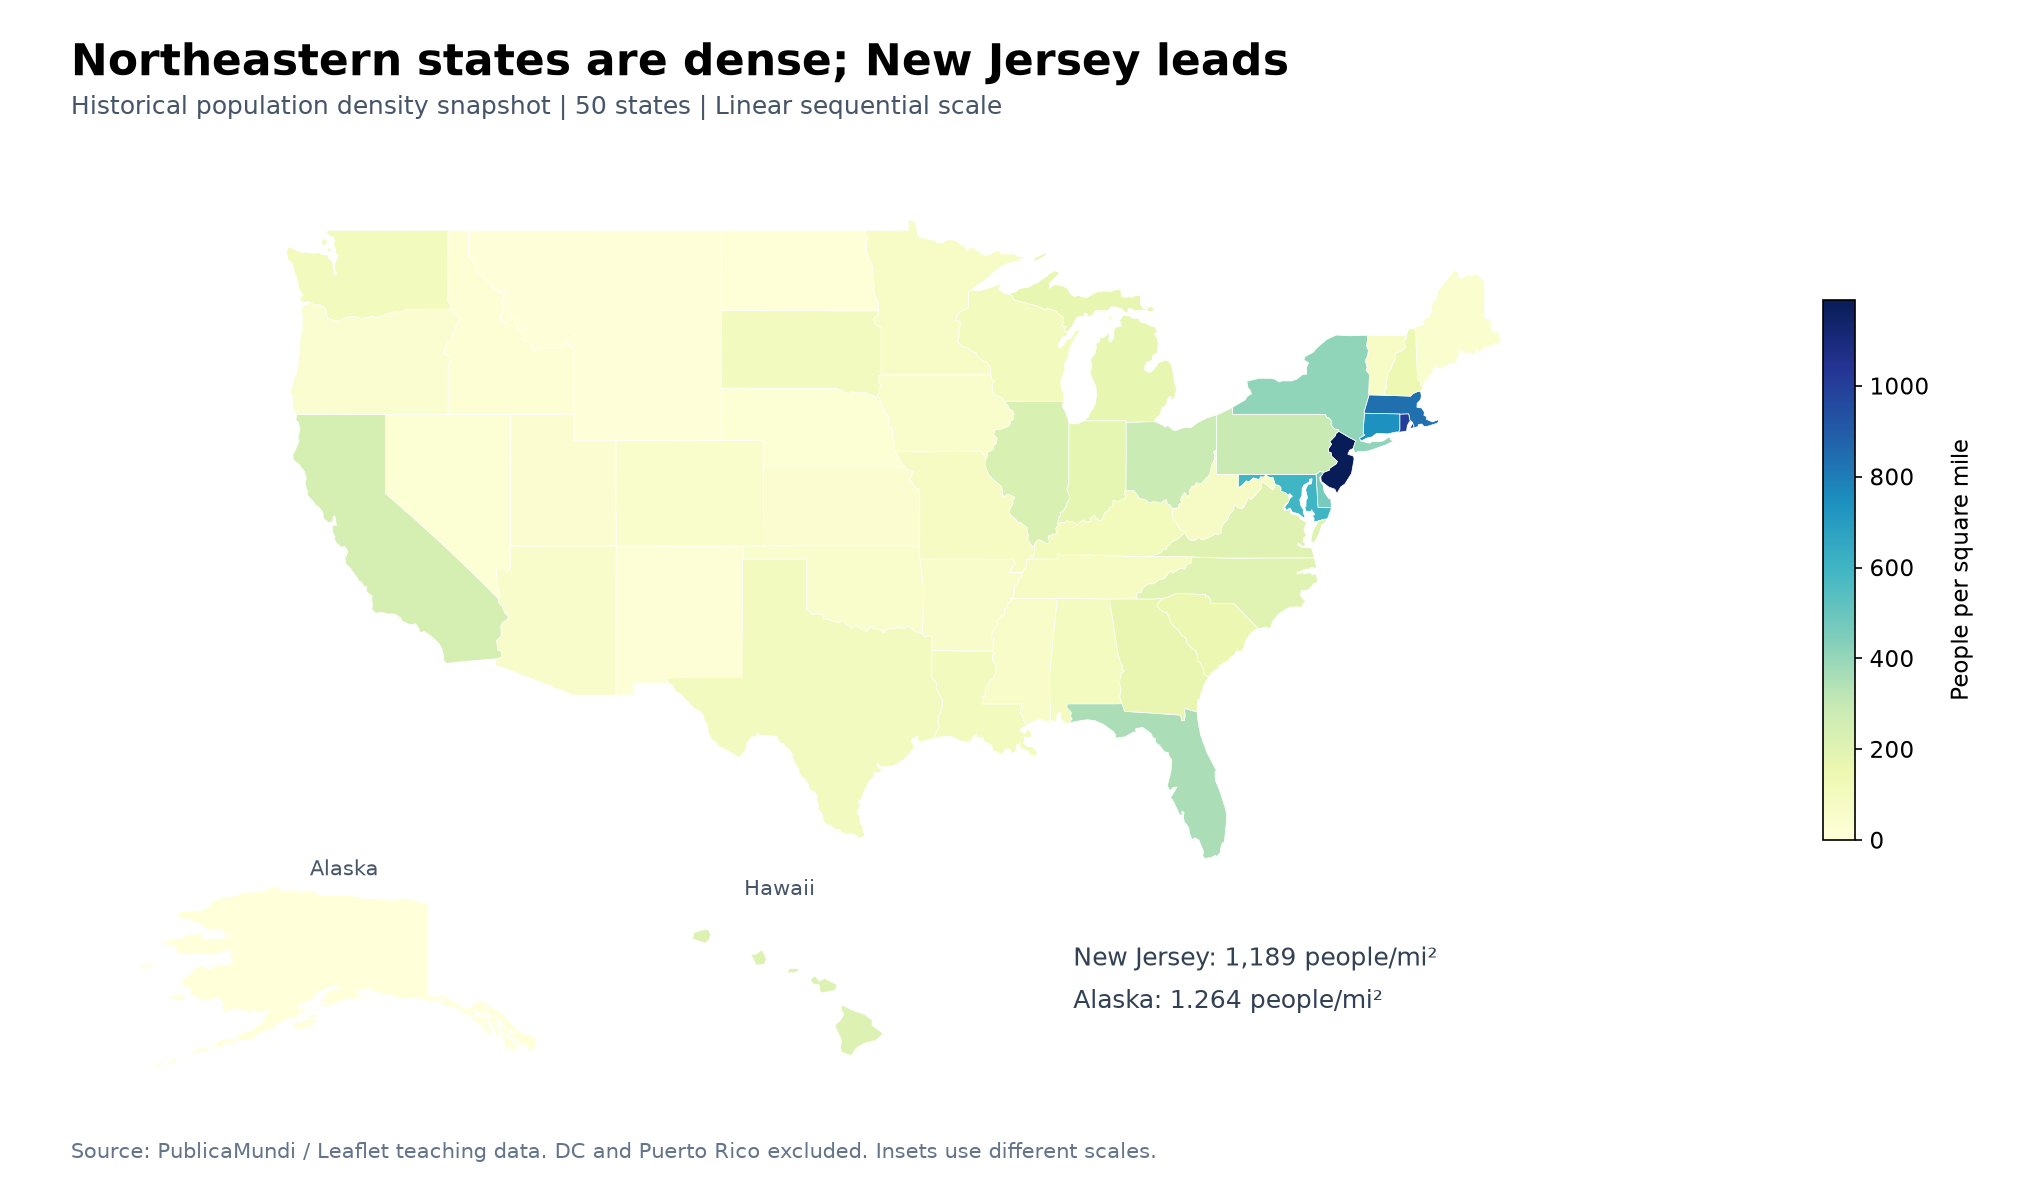

In [8]:
# Display a bundled PNG as a standard notebook image output.
# This works without attachment support, internet access, or extra files.
import base64
from IPython.display import Image, display
chart_png_base64 = (
    '...'
    'AAAAmMYCtyvQ+9i+XFYAAAAASUVORK5CYII='
)
display(Image(data=base64.b64decode(chart_png_base64), format="png", width=1000))

In [9]:
ranking = state_data.sort_values('Density', ascending=False)
top, bottom = ranking.iloc[0], ranking.iloc[-1]
display(Markdown(
    f"**Interpretation.** {top['State']} has the highest state density "
    f"(**{top['Density']:,.2f} people/mi²**) in this snapshot. "
    "Rhode Island, Massachusetts and Connecticut also rank near the top, showing a "
    "concentration of high state-level densities in the Northeast. "
    f"{bottom['State']} has the lowest value (**{bottom['Density']:,.3f} people/mi²**).\n\n"
    "**Limits.** State averages hide dense cities and sparsely populated rural areas. "
    "Small northeastern states can be difficult to see; hover and the ranking table aid comparison. "
    "This is a historical dataset and should not be presented as current estimates."
))

**Interpretation.** New Jersey has the highest state density (**1,189.00 people/mi²**) in this snapshot. Rhode Island, Massachusetts and Connecticut also rank near the top, showing a concentration of high state-level densities in the Northeast. Alaska has the lowest value (**1.264 people/mi²**).

**Limits.** State averages hide dense cities and sparsely populated rural areas. Small northeastern states can be difficult to see; hover and the ranking table aid comparison. This is a historical dataset and should not be presented as current estimates.

## Reuse and export
Interactive HTML files are generated in chart_exports/ locally or /kaggle/working/ on Kaggle. The pictures are stored as standard PNG cell outputs and bundled in their display cells. They appear in the downloaded notebook and redisplay when you run those cells, without separate image files.

Optional regeneration of PNG pictures requires a compatible Plotly/Kaleido installation (modern Kaleido also needs Chrome):
~~~python
fig_world.write_image(OUTPUT_DIR / 'task1_world_life_expectancy.png', scale=2)
fig_states.write_image(OUTPUT_DIR / 'task2_us_state_density.png', scale=2)
~~~

**Checklist:** two requested maps; justified chart types and colour scales; zero-centred deviation scale; informative hover fields; geographic insight titles; GeoJSON property inspection and validated joins; interpretations; saved chart pictures.

## Reproducible static pictures
The required maps above use Plotly Express. The code below also creates PNG companion maps using Matplotlib so that rerunning does not require Kaleido or Chrome. Colours and numeric limits match the interactive charts; the static projections are simpler. Both PNGs are also embedded above for immediate viewing.

World outline source: [johan/world.geo.json](https://github.com/johan/world.geo.json/blob/master/countries.geo.json). The public GeoJSON snapshot is embedded, just like the state geometry.

In [10]:
WORLD_GEOJSON_GZIP_BASE64 = '...'

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable

world_shapes = json.loads(gzip.decompress(base64.b64decode(WORLD_GEOJSON_GZIP_BASE64)))

def draw_regions(ax, features, values, key, cmap, norm):
    patches, colors = [], []
    for feature in features:
        geometry = feature.get('geometry')
        if not geometry:
            continue
        region = key(feature)
        value = values.get(region)
        color = '#e5e7eb' if value is None else cmap(norm(value))
        polys = geometry['coordinates']
        if geometry['type'] == 'Polygon':
            polys = [polys]
        for polygon in polys:
            # Exterior outlines suffice at this small world/state overview scale.
            patches.append(Polygon(polygon[0], closed=True))
            colors.append(color)
    ax.add_collection(PatchCollection(patches, facecolors=colors,
                                     edgecolors='white', linewidths=0.35))
    ax.set_axis_off()

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})
world_cmap = LinearSegmentedColormap.from_list('plotly_RdBu', [tuple(v/255 for v in px.colors.unlabel_rgb(c)) for c in px.colors.diverging.RdBu])
world_norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)
world_values = gm_2007.set_index('iso_alpha')['deviation'].to_dict()
fig, ax = plt.subplots(figsize=(13.5, 7.4))
fig.subplots_adjust(left=.025, right=.9, top=.81, bottom=.12)
draw_regions(ax, world_shapes['features'], world_values, lambda f: f['id'], world_cmap, world_norm)
ax.set_xlim(-180, 180)
ax.set_ylim(-60, 85)
ax.set_aspect('equal')
fig.suptitle('Africa is furthest below the global country mean',
             x=.035, ha='left', y=.97, fontsize=21, fontweight='bold')
fig.text(.035, .9, f'Gapminder 2007 | Country mean: {global_mean:.2f} years | Red below; blue above',
         fontsize=12, color='#475569')
cax = fig.add_axes([.92, .23, .016, .5])
cb = fig.colorbar(ScalarMappable(norm=world_norm, cmap=world_cmap), cax=cax)
cb.set_label('Years relative to mean', labelpad=10)
fig.text(.035, .055, 'Source: Plotly / Gapminder; world.geo.json outlines. Grey = no data. Equal country weights.',
         fontsize=10, color='#64748b')
fig.savefig(OUTPUT_DIR / 'task1_world_life_expectancy.png', dpi=150, facecolor='white')
plt.close(fig)

state_cmap = LinearSegmentedColormap.from_list('plotly_YlGnBu', [tuple(v/255 for v in px.colors.unlabel_rgb(c)) for c in px.colors.sequential.YlGnBu])
state_norm = Normalize(vmin=0, vmax=state_data['Density'].max())
state_values = state_data.set_index('State')['Density'].to_dict()
fig = plt.figure(figsize=(13.5, 8))
ax = fig.add_axes([.035, .26, .82, .57])
main_features = [f for f in state_geojson['features']
                 if f['properties']['name'] not in {'Alaska', 'Hawaii'}]
draw_regions(ax, main_features, state_values, lambda f: f['properties']['name'], state_cmap, state_norm)
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_aspect(1.25)
for name, position, bounds in [
    ('Alaska', [.07, .08, .20, .20], (-170, -129, 51, 72)),
    ('Hawaii', [.31, .09, .15, .16], (-161, -154, 18, 23)),
]:
    inset = fig.add_axes(position)
    features = [f for f in state_geojson['features'] if f['properties']['name'] == name]
    draw_regions(inset, features, state_values, lambda f: f['properties']['name'], state_cmap, state_norm)
    inset.set_xlim(bounds[:2]); inset.set_ylim(bounds[2:])
    inset.set_aspect('equal')
    inset.set_title(name, fontsize=10, color='#475569', pad=2)
fig.suptitle('Northeastern states are dense; New Jersey leads',
             x=.035, ha='left', y=.965, fontsize=21, fontweight='bold')
fig.text(.035, .905, 'Historical population density snapshot | 50 states | Linear sequential scale',
         fontsize=12, color='#475569')
cax = fig.add_axes([.9, .3, .016, .45])
cb = fig.colorbar(ScalarMappable(norm=state_norm, cmap=state_cmap), cax=cax)
cb.set_label('People per square mile', labelpad=10)
fig.text(.53, .16, 'New Jersey: 1,189 people/mi²\nAlaska: 1.264 people/mi²',
         fontsize=12, color='#334155', linespacing=1.7)
fig.text(.035, .035, 'Source: PublicaMundi / Leaflet teaching data. DC and Puerto Rico excluded. Insets use different scales.',
         fontsize=10, color='#64748b')
fig.savefig(OUTPUT_DIR / 'task2_us_state_density.png', dpi=150, facecolor='white')
plt.close(fig)
print('Saved both reproducible PNG companion maps.')

Saved both reproducible PNG companion maps.
